In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize pixel values from 0–255 to 0–1
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)


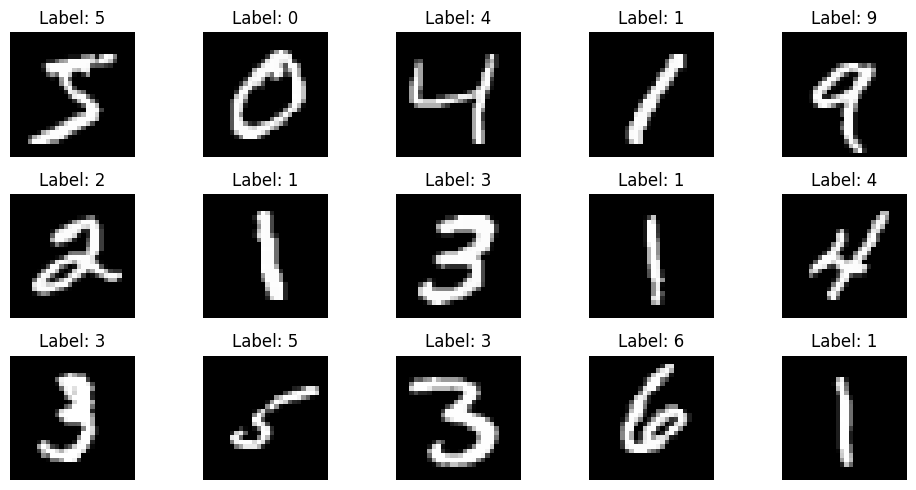

In [3]:
plt.figure(figsize=(10, 5))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
model = models.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),                 # 28 × 28 → 784
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9225 - loss: 0.2622 - val_accuracy: 0.9703 - val_loss: 0.1100
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9663 - loss: 0.1098 - val_accuracy: 0.9700 - val_loss: 0.1022
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9767 - loss: 0.0750 - val_accuracy: 0.9720 - val_loss: 0.0928
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9814 - loss: 0.0575 - val_accuracy: 0.9773 - val_loss: 0.0807
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9856 - loss: 0.0442 - val_accuracy: 0.9793 - val_loss: 0.0769
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9891 - loss: 0.0339 - val_accuracy: 0.9770 - val_loss: 0.0888
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9906 - loss: 0.0289 - val_accuracy: 0.9745 - val_loss: 0.1074
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9915 - loss: 0.0250 -

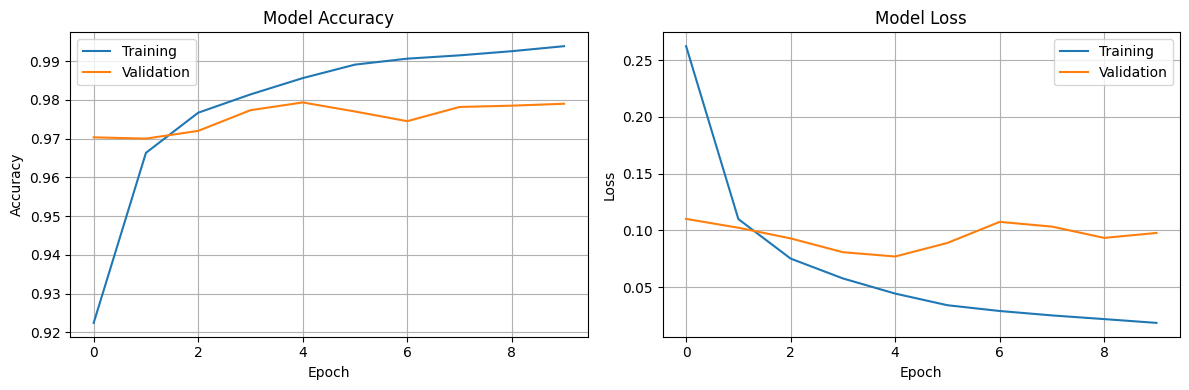

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history.history["accuracy"], label="Training")
ax[0].plot(history.history["val_accuracy"], label="Validation")
ax[0].set_title("Model Accuracy")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Accuracy")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(history.history["loss"], label="Training")
ax[1].plot(history.history["val_loss"], label="Validation")
ax[1].set_title("Model Loss")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Loss")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

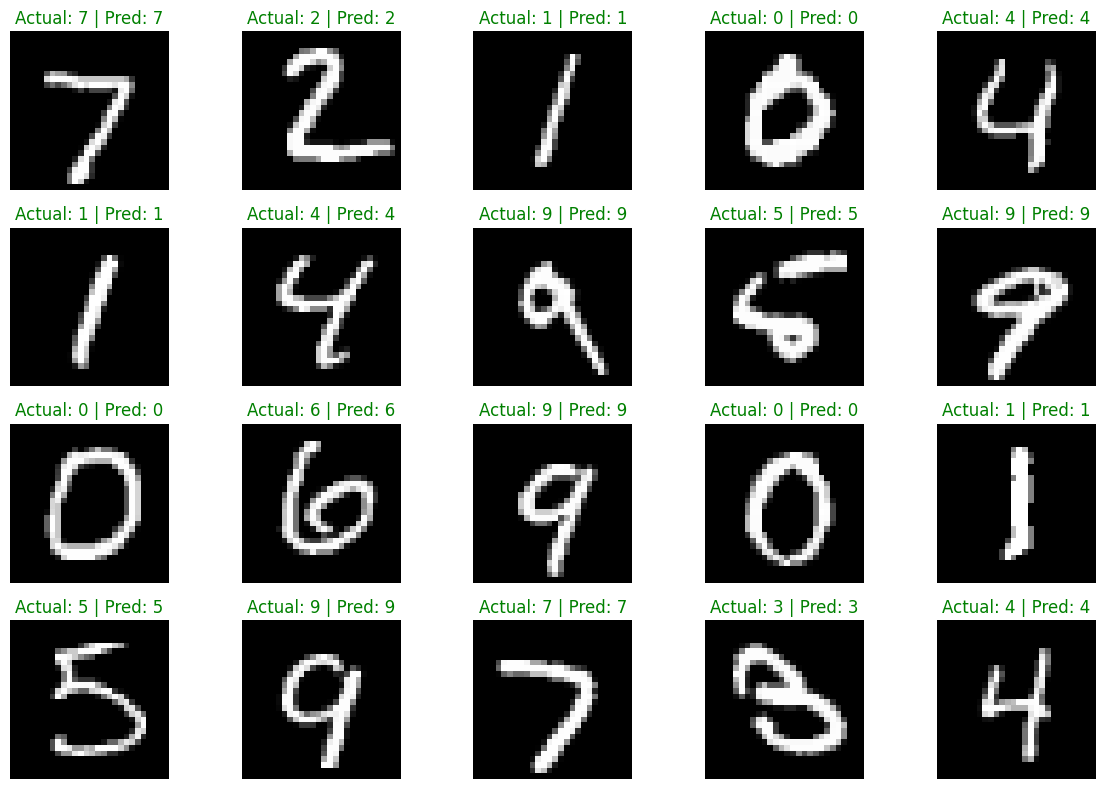

In [7]:
predictions = model.predict(X_test, verbose=0)
y_pred = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 8))

for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(X_test[i], cmap="gray")

    color = "green" if y_pred[i] == y_test[i] else "red"

    plt.title(
        f"Actual: {y_test[i]} | Pred: {y_pred[i]}",
        color=color
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

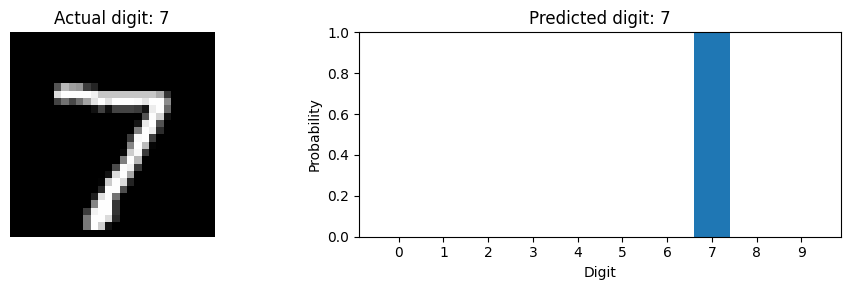

In [8]:
i = 0  # Change the index to inspect another image

plt.figure(figsize=(10, 3))

plt.subplot(1, 2, 1)
plt.imshow(X_test[i], cmap="gray")
plt.title(f"Actual digit: {y_test[i]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.bar(range(10), predictions[i])
plt.xticks(range(10))
plt.xlabel("Digit")
plt.ylabel("Probability")
plt.title(f"Predicted digit: {y_pred[i]}")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

Test accuracy: 0.9773
Test loss: 0.0929


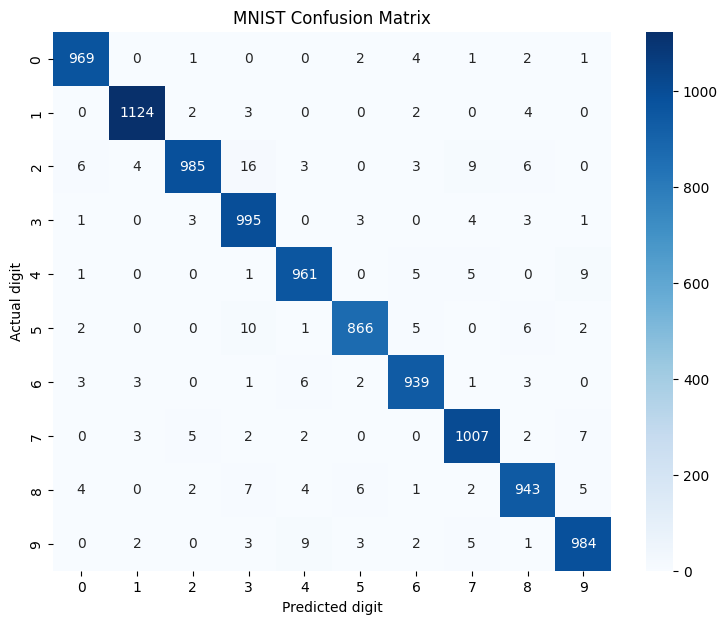

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.99      0.95      0.97      1032
           3       0.96      0.99      0.97      1010
           4       0.97      0.98      0.98       982
           5       0.98      0.97      0.98       892
           6       0.98      0.98      0.98       958
           7       0.97      0.98      0.98      1028
           8       0.97      0.97      0.97       974
           9       0.98      0.98      0.98      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



In [9]:
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test loss: {test_loss:.4f}")

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted digit")
plt.ylabel("Actual digit")
plt.title("MNIST Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred))

In [10]:
!pip install -q gradio

In [17]:

import gradio as gr
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Extract the outputs of the hidden and output layers
activation_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[
        model.layers[-3].output,  # 128 neurons
        model.layers[-2].output,  # 64 neurons
        model.layers[-1].output   # 10 output probabilities
    ]
)


def predict_and_visualize(image):
    try:
        if image is None:
            return None, "Draw a digit first!"

        # Gradio Sketchpad may return a dictionary
        if isinstance(image, dict):
            image = image.get("composite")

            if image is None:
                return None, "Please draw on the canvas and try again."

        # Convert to NumPy array
        img = np.array(image)

        # Handle RGB/RGBA images
        if img.ndim == 3:
            if img.shape[-1] == 4:
                img = img[:, :, :3]
            img = np.mean(img, axis=2)

        # Convert to uint8
        if img.max() <= 1:
            img = img * 255

        img = img.astype(np.uint8)

        # Invert white background to match MNIST
        if img.mean() > 127:
            img = 255 - img

        # Resize and normalize
        img = Image.fromarray(img).resize((28, 28))
        x = np.array(img).astype("float32") / 255.0
        x = x.reshape(1, 28, 28)

        # Get layer activations
        h1, h2, output = activation_model.predict(
            x, verbose=0
        )

        probabilities = output[0]
        prediction = int(np.argmax(probabilities))

        # Visualize each layer
        fig, ax = plt.subplots(2, 2, figsize=(12, 8))

        ax[0, 0].imshow(x[0], cmap="gray")
        ax[0, 0].set_title("Input: 28 × 28")
        ax[0, 0].axis("off")

        ax[0, 1].imshow(
            h1[0].reshape(8, 16), cmap="viridis"
        )
        ax[0, 1].set_title("Hidden Layer 1: 128 neurons")

        ax[1, 0].imshow(
            h2[0].reshape(8, 8), cmap="viridis"
        )
        ax[1, 0].set_title("Hidden Layer 2: 64 neurons")

        ax[1, 1].bar(range(10), probabilities)
        ax[1, 1].set_xticks(range(10))
        ax[1, 1].set_ylim(0, 1)
        ax[1, 1].set_title("Output probabilities")
        ax[1, 1].set_xlabel("Digit")

        plt.tight_layout()

        result = (
            f"Predicted digit: {prediction}\n"
            f"Confidence: {probabilities[prediction]*100:.2f}%\n\n"
            + "\n".join(
                f"Digit {i}: {p*100:.2f}%"
                for i, p in enumerate(probabilities)
            )
        )

        return fig, result

    except Exception as e:
        return None, f"Error: {type(e).__name__}: {e}"



with gr.Blocks() as demo:
    gr.Markdown("# MNIST Neural Network Visualizer")
    gr.Markdown(
        "Draw a digit from 0 to 9, then click Predict "
        "to see how the network processes it."
    )

    with gr.Row():
        canvas = gr.Sketchpad(type="numpy",image_mode="L",label="Draw your digit here")
        with gr.Column():
            predict_btn = gr.Button("Predict", variant="primary")
            clear_btn = gr.Button("Clear Canvas")
            result_text = gr.Textbox(
                label="Prediction",
                lines=12
            )

    visualization = gr.Plot(label="Layer Activations")

    predict_btn.click(
        fn=predict_and_visualize,
        inputs=canvas,
        outputs=[visualization, result_text]
    )

    clear_btn.click(
        fn=lambda: (None, None, ""),
        outputs=[canvas, visualization, result_text]
    )

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://67711f2ce066c68bce.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
